In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.datasets import load_breast_cancer

# Breast Cancer Dataset (Miss wala)
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['target'] = cancer.target
df['diagnosis'] = df['target'].map({0:'Malignant', 1:'Benign'})
print(df.shape)
df.head()

(569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


In [ ]:
print("--- INFO ---")
print(df.info())

print("\n--- DESCRIBE ---")
print(df.describe())

print("\n--- NULL VALUES ---")
print(df.isnull().sum())

print("\n--- DUPLICATES ---")
print(f"Duplicate rows: {df.duplicated().sum()}")

print("\n--- TARGET BALANCE ---")
print(df['diagnosis'].value_counts())

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness er

Data is already clean ✅


/tmp/ipykernel_2360/1291664332.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diagnosis', data=df_clean, palette='pastel')


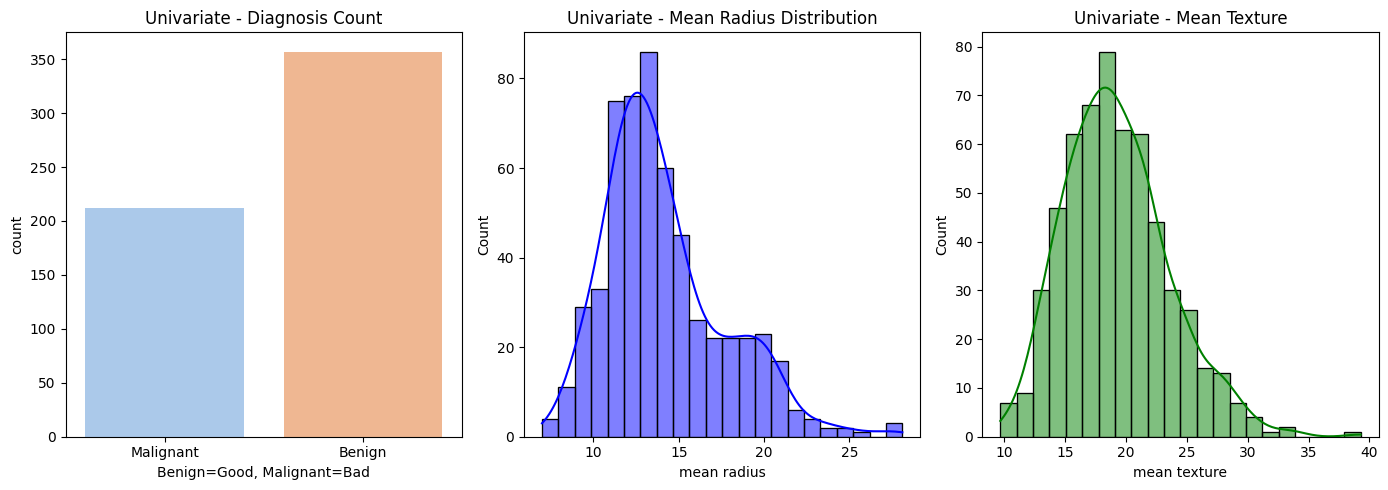

In [ ]:
# 4. Clean Data - Is dataset me cleaning ki zarurat nahi kyunki 0 null/duplicate hai
# Phir bhi Miss ke steps ke liye likh denge
df_clean = df.copy()
print("Data is already clean ✅")

# 5. Transform / Feature Engineering
# Hum diagnosis ko clearly 0/1 se naam de chuke hain

# 6. Univariate Analysis
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14,5))

# Plot 1: Diagnosis Count
plt.subplot(1,3,1)
sns.countplot(x='diagnosis', data=df_clean, palette='pastel')
plt.title('Univariate - Diagnosis Count')
plt.xlabel('Benign=Good, Malignant=Bad')

# Plot 2: Mean Radius Distribution
plt.subplot(1,3,2)
sns.histplot(df_clean['mean radius'], kde=True, color='blue')
plt.title('Univariate - Mean Radius Distribution')

# Plot 3: Mean Texture
plt.subplot(1,3,3)
sns.histplot(df_clean['mean texture'], kde=True, color='green')
plt.title('Univariate - Mean Texture')

plt.tight_layout()
plt.show()

/tmp/ipykernel_2360/4110081691.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='diagnosis', y='mean radius', data=df_clean, palette='Set2')


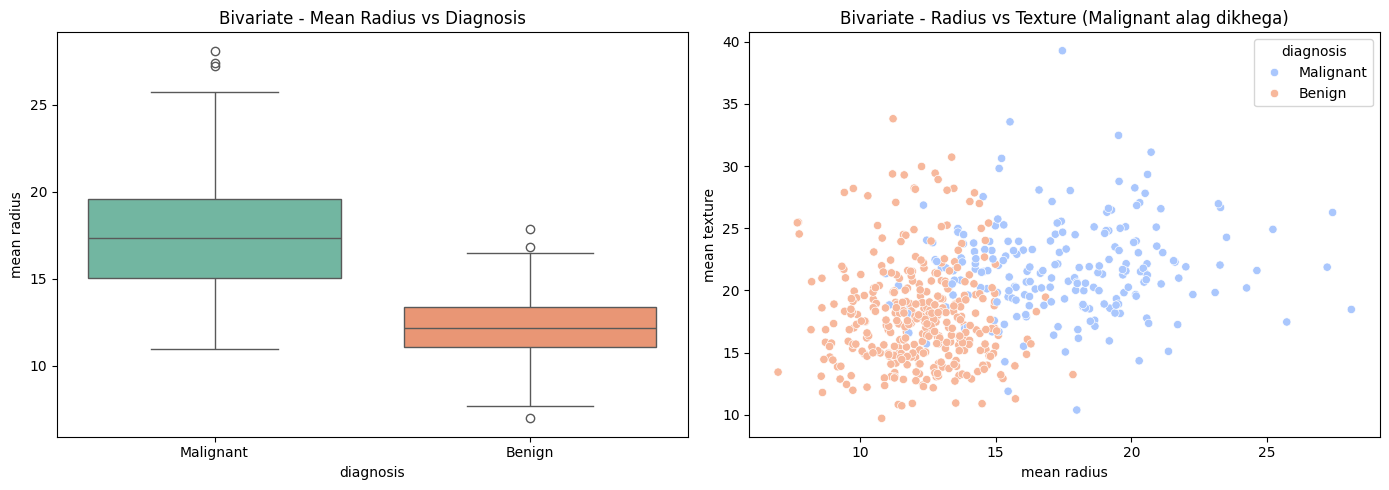

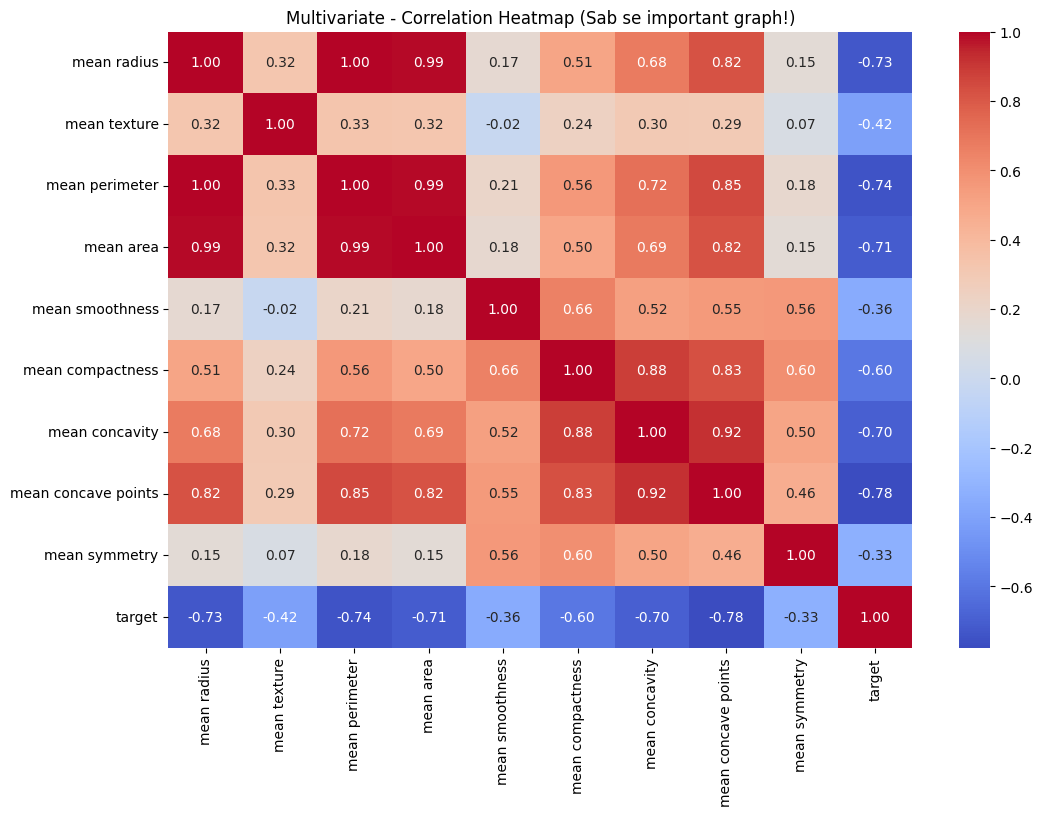

In [ ]:
# 7. Bivariate Analysis - 2 cheezon ka relation

plt.figure(figsize=(14,5))

# Bivariate 1: Radius vs Diagnosis
plt.subplot(1,2,1)
sns.boxplot(x='diagnosis', y='mean radius', data=df_clean, palette='Set2')
plt.title('Bivariate - Mean Radius vs Diagnosis')

# Bivariate 2: Radius vs Texture with Diagnosis color
plt.subplot(1,2,2)
sns.scatterplot(x='mean radius', y='mean texture', hue='diagnosis', data=df_clean, palette='coolwarm')
plt.title('Bivariate - Radius vs Texture (Malignant alag dikhega)')

plt.tight_layout()
plt.show()

# 8. Multivariate Analysis - Heatmap
plt.figure(figsize=(12,8))
# Sirf important 10 columns ka correlation
cols = ['mean radius','mean texture','mean perimeter','mean area','mean smoothness','mean compactness','mean concavity','mean concave points','mean symmetry','target']
sns.heatmap(df_clean[cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Multivariate - Correlation Heatmap (Sab se important graph!)')
plt.show()